# 03 · Modelado supervisado — Bike Sharing Demand

**Responsable de este notebook:** Joan · **Plan:** `project_plan_crisp_dm.md` §6 · Pardo y José entregan sus modelos en `03b_ridge.ipynb` y `03c_random_forest.ipynb`; Joan consolida la tabla.

**Contenido:** Parte I, **baselines** (§6.1, Sprint 1); Parte II, **LightGBM** con ablaciones, tuning, Poisson, *smearing* y lags (Sprint 2).

**Protocolo:** todo con **train** (2011-01-01 a 2012-06-30) y `TimeSeriesSplit` (ventana expansiva, 5 folds). El test (jul–dic 2012) **no se usa** en este notebook. Métrica de decisión: **RMSLE**.


## 1) Preparación del entorno

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

for _p in [Path.cwd(), *Path.cwd().parents]:
    if (_p / "config" / "config.py").exists():
        RAIZ = _p
        break
else:
    raise FileNotFoundError("No se encontró config/config.py")
sys.path.insert(0, str(RAIZ))

from config.config import CONFIG, RANDOM_STATE
from src.data_loader import load_data, temporal_split, separar_xy
from src.evaluate import rmsle, evaluar_pipeline, get_cv, validar_temporal

sns.set_theme(style="whitegrid")
FIG_DIR = CONFIG["dir_reports"] / "joan" / "figuras"; FIG_DIR.mkdir(parents=True, exist_ok=True)
print("RANDOM_STATE =", RANDOM_STATE, "| CV:", CONFIG["cv"])

RANDOM_STATE = 42 | CV: {'n_splits': 5, 'test_size': 1460, 'gap': 0, 'max_train_size': None}


### ✅ Punto de control 1

In [2]:
assert RANDOM_STATE == 42 and CONFIG["cv"]["n_splits"] == 5
print("✅ Configuración lista.")

✅ Configuración lista.


## 2) Datos de train y validación temporal

Se carga la serie completa (para mantener la continuidad horaria), se parte en train/test y **se descarta el test inmediatamente**: a partir de aquí solo existe `X_tr`, `y_tr`.

In [3]:
df = load_data()
train, test = temporal_split(df)
X_tr, y_tr = separar_xy(train)
del test  # el test no se usa en este notebook
print("X_tr:", X_tr.shape, "| y_tr:", y_tr.shape, "| rango:", X_tr.index.min(), "->", X_tr.index.max())

cv = get_cv()
print(cv)
filas = []
for k, (i_tr, i_va) in enumerate(cv.split(X_tr), start=1):
    filas.append({"fold": k, "n_train": len(i_tr), "train_hasta": X_tr.index[i_tr[-1]], "val_desde": X_tr.index[i_va[0]], "val_hasta": X_tr.index[i_va[-1]], "n_val": len(i_va)})
tabla_folds = pd.DataFrame(filas)
display(tabla_folds)

X_tr: (13003, 13) | y_tr: (13003,) | rango: 2011-01-01 00:00:00 -> 2012-06-30 23:00:00
TimeSeriesSplit(gap=0, max_train_size=None, n_splits=5, test_size=1460)


,fold,n_train,train_hasta,val_desde,val_hasta,n_val
0,1,5703,2011-08-31 01:00:00,2011-08-31 02:00:00,2011-10-31 01:00:00,1460
1,2,7163,2011-10-31 01:00:00,2011-10-31 02:00:00,2011-12-31 01:00:00,1460
2,3,8623,2011-12-31 01:00:00,2011-12-31 02:00:00,2012-03-01 04:00:00,1460
3,4,10083,2012-03-01 04:00:00,2012-03-01 05:00:00,2012-05-01 03:00:00,1460
4,5,11543,2012-05-01 03:00:00,2012-05-01 04:00:00,2012-06-30 23:00:00,1460


### ✅ Punto de control 2: sin fuga temporal

In [4]:
assert X_tr.index.max() <= pd.Timestamp(CONFIG["ultima_hora_train"])
assert y_tr.notna().all() and (y_tr >= 1).all()
assert not {"cnt", "casual", "registered", "instant"} & set(X_tr.columns)
assert (tabla_folds["train_hasta"] < tabla_folds["val_desde"]).all()
assert tabla_folds["val_desde"].is_monotonic_increasing, "las ventanas de validación deben avanzar en el tiempo"
assert (tabla_folds["val_hasta"].iloc[:-1].to_numpy() < tabla_folds["val_desde"].iloc[1:].to_numpy()).all(), "las ventanas se solapan"
print("✅ En cada fold el train es anterior a la validación; las ventanas no se solapan; el test no está cargado.")

✅ En cada fold el train es anterior a la validación; las ventanas no se solapan; el test no está cargado.


**Interpretación.** Los 5 folds usan ventana expansiva: el primero entrena con 5 703 filas (≈ 8 meses, del 2011-01-01 al 2011-08-31) y valida 1 460 filas (≈ 2 meses); cada fold siguiente añade 1 460 filas de train. En todos los folds el train es anterior a la validación y las ventanas no se solapan, así que no hay fuga temporal. **Ojo:** las ventanas de validación cubren del 2011-08-31 al 2012-06-30 y no incluyen julio ni agosto, que sí están en el test. Además, los últimos folds validan en 2012 con modelos entrenados mayormente con 2011, cuando la demanda era menor (ver sección 5b).

## 3) Baseline heurístico (§6.1): media de `cnt` por `(hr, workingday)`

Referencia simple basada solo en calendario. Se implementa como estimador de scikit-learn para poder usarlo en la misma validación que los demás modelos: `fit` calcula la media por grupo **solo con las filas que recibe** (el train de cada fold).

In [5]:
class MediaPorGrupo(BaseEstimator, RegressorMixin):
    """Predice la media del target del grupo (hr, workingday) aprendida en fit. Sin hiperparámetros."""

    def fit(self, X, y):
        datos = pd.DataFrame({"hr": X["hr"].to_numpy(), "workingday": X["workingday"].to_numpy(), "y": np.asarray(y, dtype=float)})
        self.medias_ = datos.groupby(["hr", "workingday"])["y"].mean()
        self.media_global_ = float(datos["y"].mean())
        return self

    def predict(self, X):
        clave = pd.MultiIndex.from_arrays([X["hr"].to_numpy(), X["workingday"].to_numpy()])
        return self.medias_.reindex(clave).fillna(self.media_global_).to_numpy()

# Inspección del ajuste sobre todo train (solo para ver la tabla aprendida)
demo = MediaPorGrupo().fit(X_tr, y_tr)
print("Grupos aprendidos:", len(demo.medias_), "| media global:", round(demo.media_global_, 1))
display(demo.medias_.unstack().round(1).loc[[0, 3, 8, 12, 17, 22]].T.rename_axis("workingday"))

Grupos aprendidos: 48 | media global: 167.7


hr,0,3,8,12,17,22
workingday,,,,,,
0,79.3,23.4,92.1,325.8,295.4,106.0
1,32.4,4.5,418.4,174.4,461.7,123.6


### ✅ Punto de control 3: el baseline es consistente

In [6]:
assert len(demo.medias_) == 48
pred_demo = demo.predict(X_tr)
assert np.isfinite(pred_demo).all() and (pred_demo > 0).all()
# Predecir un grupo = su media aprendida
fila = X_tr.iloc[[0]]
assert np.isclose(demo.predict(fila)[0], y_tr[(X_tr["hr"] == fila["hr"].iloc[0]) & (X_tr["workingday"] == fila["workingday"].iloc[0])].mean())
print("✅ 48 grupos (24 horas x 2 tipos de día); la predicción coincide con la media del grupo.")

✅ 48 grupos (24 horas x 2 tipos de día); la predicción coincide con la media del grupo.


### Validación temporal del baseline heurístico
Se reporta en las dos formas razonables para no esconder una elección: el plan dice **media de `cnt`** (en bicicletas, `log_target=False`); la variante en log promedia `log1p(cnt)` y revierte con `expm1`.

In [7]:
res = []
folds = {}
for nombre, log_t in [("Media (hr, workingday) · plan: media de cnt", False), ("Media (hr, workingday) · variante: media de log1p", True)]:
    por_fold, resumen = validar_temporal(MediaPorGrupo(), X_tr, y_tr, nombre=nombre, cv=cv, log_target=log_t)
    folds[nombre] = por_fold; res.append(resumen)
    print(nombre); display(por_fold[["fold", "n_train", "n_val", "rmsle", "rmse", "mae", "r2"]].round(4))

Media (hr, workingday) · plan: media de cnt


,fold,n_train,n_val,rmsle,rmse,mae,r2
0,1,5703,1460,0.4960,79.8460,56.5323,0.7048
1,2,7163,1460,0.5902,64.5773,40.9951,0.6931
2,3,8623,1460,0.4949,58.8304,39.1020,0.7852
3,4,10083,1460,0.5826,145.1223,99.6831,0.4892
4,5,11543,1460,0.6286,165.5415,125.3248,0.4242


Media (hr, workingday) · variante: media de log1p


,fold,n_train,n_val,rmsle,rmse,mae,r2
0,1,5703,1460,0.5708,96.0191,69.0293,0.5731
1,2,7163,1460,0.5404,60.9391,40.7740,0.7267
2,3,8623,1460,0.4453,60.7241,40.1362,0.7712
3,4,10083,1460,0.6720,162.3437,113.5908,0.3608
4,5,11543,1460,0.7616,187.6358,143.3034,0.2602


## 4) Baseline paramétrico (§6.1): `LinearRegression` sobre variables numéricas crudas

Sin ingeniería de variables: las 12 columnas numéricas originales tal cual (incluye `atemp` y `weathersit = 4`). `casual`, `registered`, `instant` y `dteday` no se seleccionan, por lo que no pueden entrar. Se entrena sobre `log1p(cnt)` para que el objetivo sea coherente con el RMSLE; como sensibilidad se muestra también el ajuste directo sobre `cnt`.

In [8]:
COLS_CRUDAS = ["season", "yr", "mnth", "hr", "holiday", "weekday", "workingday", "weathersit", "temp", "atemp", "hum", "windspeed"]
assert len(COLS_CRUDAS) == 12 and not {"casual", "registered", "instant", "dteday", "cnt"} & set(COLS_CRUDAS)

def lineal_crudo():
    sel = ColumnTransformer([("num", "passthrough", COLS_CRUDAS)], remainder="drop", verbose_feature_names_out=False)
    return Pipeline([("seleccion", sel), ("lr", LinearRegression())])

# Qué columnas ve realmente el modelo
vista = lineal_crudo().fit(X_tr, np.log1p(y_tr))
print("Columnas que entran al modelo:", vista.named_steps["lr"].n_features_in_, "->", list(vista.named_steps["seleccion"].get_feature_names_out()))
coef = pd.Series(vista.named_steps["lr"].coef_, index=COLS_CRUDAS).round(4)
display(coef.to_frame("coeficiente (sobre log1p)").T)

for nombre, log_t in [("LinearRegression cruda · objetivo log1p", True), ("LinearRegression cruda · objetivo cnt (sensibilidad)", False)]:
    por_fold, resumen = validar_temporal(lineal_crudo(), X_tr, y_tr, nombre=nombre, cv=cv, log_target=log_t)
    folds[nombre] = por_fold; res.append(resumen)
    print(nombre); display(por_fold[["fold", "n_train", "n_val", "rmsle", "rmse", "mae", "r2"]].round(4))

Columnas que entran al modelo: 12 -> ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']


,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed
coeficiente (sobre log1p),0.1081,0.4853,0.0146,0.0974,-0.1777,0.0161,-0.0552,-0.0238,-0.0515,2.3819,-1.2426,0.3206


LinearRegression cruda · objetivo log1p


,fold,n_train,n_val,rmsle,rmse,mae,r2
0,1,5703,1460,1.1055,157.7602,109.3350,-0.1525
1,2,7163,1460,1.0408,114.4868,78.4165,0.0353
2,3,8623,1460,1.2535,141.0544,95.1980,-0.2345
3,4,10083,1460,1.1213,192.8802,135.7581,0.0977
4,5,11543,1460,1.0063,224.1546,158.7830,-0.0558


LinearRegression cruda · objetivo cnt (sensibilidad)


,fold,n_train,n_val,rmsle,rmse,mae,r2
0,1,5703,1460,1.0973,129.4005,90.4732,0.2246
1,2,7163,1460,1.1997,101.5736,77.4601,0.2407
2,3,8623,1460,1.5870,125.9791,82.6873,0.0152
3,4,10083,1460,1.3139,176.2491,131.0373,0.2466
4,5,11543,1460,1.2613,183.0393,145.6312,0.2960


### ✅ Punto de control 4: métricas válidas en cada fold

In [9]:
for nombre, f in folds.items():
    assert len(f) == 5, nombre
    assert np.isfinite(f[["rmsle", "rmse", "mae", "r2"]].to_numpy()).all(), nombre
    assert (f["rmsle"] > 0).all()
print("✅ 4 variantes x 5 folds con métricas finitas.")

✅ 4 variantes x 5 folds con métricas finitas.


## 5) Tabla comparativa de baselines (validación temporal, solo train)

,rmsle_media,rmsle_std,rmse_media,rmse_std,mae_media,mae_std,r2_media,r2_std
modelo,,,,,,,,
"Media (hr, workingday) · plan: media de cnt",0.5585,0.0601,102.7835,49.1143,72.3275,38.3803,0.6193,0.1543
"Media (hr, workingday) · variante: media de log1p",0.5980,0.1221,113.5324,58.5989,81.3667,45.7561,0.5384,0.2235
LinearRegression cruda · objetivo log1p,1.1055,0.0951,166.0672,43.1517,115.4981,32.0514,-0.0620,0.1351
LinearRegression cruda · objetivo cnt (sensibilidad),1.2918,0.1836,143.2483,34.9969,105.4578,30.8023,0.2046,0.1092


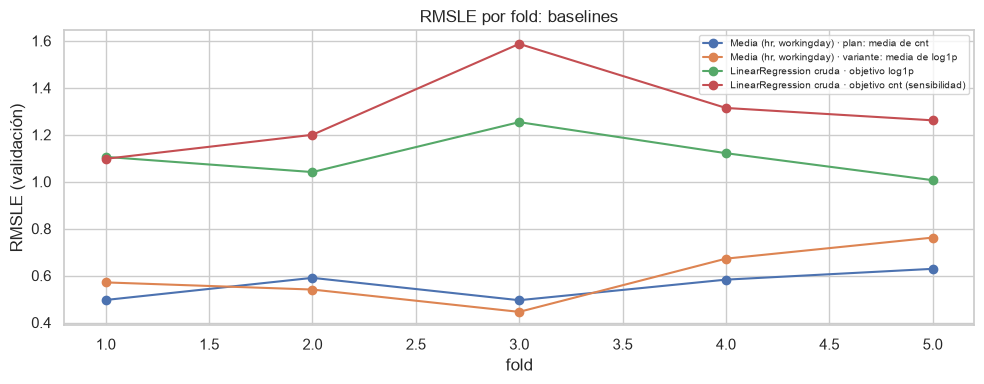

,"Media (hr, workingday) · plan: media de cnt","Media (hr, workingday) · variante: media de log1p",LinearRegression cruda · objetivo log1p,LinearRegression cruda · objetivo cnt (sensibilidad)
fold,,,,
1,0.4960,0.5708,1.1055,1.0973
2,0.5902,0.5404,1.0408,1.1997
3,0.4949,0.4453,1.2535,1.5870
4,0.5826,0.6720,1.1213,1.3139
5,0.6286,0.7616,1.0063,1.2613


In [10]:
tabla = pd.DataFrame(res).set_index("modelo")
orden = ["rmsle_media", "rmsle_std", "rmse_media", "rmse_std", "mae_media", "mae_std", "r2_media", "r2_std"]
display(tabla[orden].round(4).sort_values("rmsle_media"))

rms = pd.DataFrame({k: v["rmsle"].to_numpy() for k, v in folds.items()}, index=range(1, 6)); rms.index.name = "fold"
fig, ax = plt.subplots(figsize=(10, 4))
rms.plot(marker="o", ax=ax); ax.set_ylabel("RMSLE (validación)"); ax.set_title("RMSLE por fold: baselines")
ax.legend(fontsize=7); plt.tight_layout(); fig.savefig(FIG_DIR / "09_baselines_rmsle_por_fold.png", dpi=130, bbox_inches="tight"); plt.show()
display(rms.round(4))

### ✅ Punto de control 5

In [11]:
assert tabla.shape[0] == 4
mejor = tabla["rmsle_media"].idxmin()
print("Baseline con menor RMSLE medio de validación:", mejor, "->", round(float(tabla.loc[mejor, 'rmsle_media']), 4))
# Las cifras de la tabla provienen de los folds mostrados
for nombre in tabla.index:
    assert np.isclose(tabla.loc[nombre, "rmsle_media"], folds[nombre]["rmsle"].mean())
print("✅ La tabla coincide con la media de los folds.")

Baseline con menor RMSLE medio de validación: Media (hr, workingday) · plan: media de cnt -> 0.5585
✅ La tabla coincide con la media de los folds.


**Interpretación.** Referencia para todo lo que sigue (validación temporal, solo train):

| Baseline | RMSLE medio ± std | RMSE medio | MAE medio | R² medio |
| :--- | :---: | :---: | :---: | :---: |
| Media por `(hr, workingday)` (plan: media de `cnt`) | **0.5585 ± 0.0601** | 102.8 | 72.3 | 0.619 |
| Media por `(hr, workingday)` (variante: media de `log1p`) | 0.5980 ± 0.1221 | 113.5 | 81.4 | 0.538 |
| `LinearRegression` cruda, objetivo `log1p` | 1.1055 ± 0.0951 | 166.1 | 115.5 | −0.062 |
| `LinearRegression` cruda, objetivo `cnt` | 1.2918 ± 0.1836 | 143.2 | 105.5 | 0.205 |

1. **El baseline de calendario es el más fuerte de los dos.** Con solo 48 medias (hora × tipo de día) explica ≈ 62 % de la varianza en promedio y supera con claridad a la regresión lineal cruda. Esto concuerda con el EDA: la hora y su interacción con el tipo de día concentran la señal.
2. **La regresión lineal cruda es peor porque su forma es inadecuada, no por un error de código** (ver 5b): trata `hr`, `mnth` o `weekday` como variables numéricas lineales, mientras que la demanda por hora tiene dos picos (no monótona). Esto justifica en los datos la categoría `hr_workingday` y los modelos no lineales; aún no mide cuánto ayuda cada uno (⏳ Sprint 2).
3. **Dentro del baseline de calendario, el promedio de `cnt` supera a la variante en log** en RMSLE medio (0.5585 frente a 0.5980) y es menos inestable entre folds. Es una comparación de dos baselines y no un resultado sobre modelos finales; se conserva el del plan como referencia.
4. **El error crece en los folds 4 y 5** (RMSLE 0.583 y 0.629; R² 0.489 y 0.424, frente a R² de 0.69–0.79 en los folds 1–3). Es el síntoma que el plan anticipa por la tendencia de crecimiento (§2.4); la sección 5b lo cuantifica.

**Umbral de éxito (§2.3, ⏳ decisión del grupo):** propuesta para discutir, no decidida: tomar como referencia el RMSLE medio de **0.5585** del baseline de calendario y definir cuánta mejora relativa se exige a los modelos.

## 5b) Diagnóstico: ¿por qué fallan los baselines?
Dos comprobaciones sobre train (sin test): (1) el error del lineal **dentro de la muestra** de entrenamiento, para distinguir mala especificación de un posible error de código; (2) el sesgo del baseline por fold, comparando la demanda real de la ventana de validación con lo que el baseline predice.

In [12]:
# (1) Lineal crudo: ajuste en toda la muestra de train
from src.evaluate import ajustar, predecir_bicis
lin_full = ajustar(lineal_crudo(), X_tr, y_tr, log_target=True)
rmsle_in = rmsle(y_tr, predecir_bicis(lin_full, X_tr, log_target=True))
r2_log_in = float(lin_full.score(X_tr, np.log1p(y_tr)))
print(f"LinearRegression cruda, dentro de train: RMSLE = {rmsle_in:.4f} | R² en escala log = {r2_log_in:.4f}")

# (2) Sesgo del baseline por fold: log1p(real) - log1p(predicho); > 0 significa que el baseline subestima
filas = []
for k, (i_tr, i_va) in enumerate(cv.split(X_tr), start=1):
    m = MediaPorGrupo().fit(X_tr.iloc[i_tr], y_tr.iloc[i_tr])
    p = m.predict(X_tr.iloc[i_va]); real = y_tr.iloc[i_va].to_numpy()
    filas.append({"fold": k, "cnt real medio (val)": real.mean(), "cnt predicho medio": p.mean(),
                  "sesgo medio en log (real - pred)": float(np.mean(np.log1p(real) - np.log1p(p)))})
sesgo = pd.DataFrame(filas).set_index("fold")
display(sesgo.round(3))

LinearRegression cruda, dentro de train: RMSLE = 1.0175 | R² en escala log = 0.4779


,cnt real medio (val),cnt predicho medio,sesgo medio en log (real - pred)
fold,,,
1,172.813,138.532,0.121
2,130.628,145.572,-0.230
3,138.578,142.867,-0.186
4,232.280,142.405,0.323
5,273.033,153.858,0.512


### ✅ Punto de control 6

In [13]:
assert rmsle_in > 0.8, "el lineal crudo debería ajustar mal incluso dentro de train si el problema es de especificación"
assert np.isfinite(sesgo.to_numpy()).all()
print("✅ Diagnóstico calculado solo con datos de train.")

✅ Diagnóstico calculado solo con datos de train.


**Interpretación.**
- **Lineal crudo:** incluso ajustado y evaluado sobre la misma muestra de train, su RMSLE es 1.0175 y su R² en escala log es 0.478. Es decir, la forma lineal en variables crudas no logra describir los datos; que valide mal no se debe a un problema de partición ni de código.
- **Sesgo del baseline por fold** (tabla anterior): en los folds 1 a 3 el sesgo es pequeño y de signo variable (+0.121, −0.230, −0.186), pero en los folds 4 y 5 el baseline **subestima de forma sistemática**: la demanda real media de la ventana de validación es 232.3 y 273.0 bicicletas/hora y el baseline predice 142.4 y 153.9 (sesgo +0.323 y +0.512 en escala log). Las medias por grupo se aprenden con meses mayoritariamente de 2011, cuando la demanda era más baja (EDA, sección 7). 🔶 Esto es coherente con una tendencia de crecimiento (y con la estacionalidad: los folds 4 y 5 validan en primavera), pero este diagnóstico por sí solo no separa ambas causas; la ablación de tendencia (`yr` / `sin_yr` / `trend`) del Sprint 2 es lo que lo medirá.
- **Consecuencia para el test:** como el test (jul–dic 2012) está aún más lejos del train, hay que esperar este mismo tipo de sesgo en un modelo sin variable de tendencia; el RMSLE mensual en test (Sprint 4) lo verificará. ⏳

---
# PARTE II · LightGBM (Sprint 2, Joan)

Modelo principal (§6.2–6.4). Todo con **train** y el mismo `TimeSeriesSplit` de los baselines (salvo el experimento de lags, que usa `gap=24` según §4.1). Métrica de decisión: **RMSLE medio de validación**; el test sigue sin cargarse.

**Orden de los experimentos** (cada prueba contra la referencia vigente, una variable a la vez):
1. LightGBM base con el preprocesador provisional de `CONFIG`.
2. Ablaciones de tendencia, `windspeed = 0` y `hum = 0` (§4.2, §4.3).
3. Tuning con `RandomizedSearchCV` + `TimeSeriesSplit`.
4. `log1p` + MSE vs objetivo Poisson; sesgo de la reversión del log (factor de *smearing* de Duan).
5. Extra: lags de 24 h y 168 h.
6. Guardar el pipeline candidato con `joblib`.

**Regla de adopción (fijada antes de ver resultados, en `CONFIG["regla_adopcion"]`):** una variante se adopta solo si mejora el RMSLE medio al menos en 0.002 **y** no empeora en más de 1 de los 5 folds (un empate no cuenta como empeorar). Es una propuesta de Joan para cumplir §2.1 punto 4 («mejora consistente entre folds»); el grupo puede ajustarla. Cada prueba queda registrada en `reports/decisiones.md`.

## 7) Preparación y LightGBM base

In [14]:
import time
import joblib
from lightgbm import LGBMRegressor
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import make_scorer
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint, uniform

from src.features import build_preprocessor, agregar_lags
from src.evaluate import ajustar, predecir_bicis, calcular_metricas

CFG_LGBM = CONFIG["lgbm"]
REGLA = CONFIG["regla_adopcion"]
PARAMS_BASE = dict(CFG_LGBM["params_base"])
print("Parámetros base de LightGBM:", PARAMS_BASE)
print("Regla de adopción:", REGLA)

def pipe_lgbm(params=None, **prep_kw):
    """Pipeline = preprocesador de src.features + LGBMRegressor. `prep_kw` se pasa a build_preprocessor."""
    p = dict(PARAMS_BASE); p.update(params or {})
    return Pipeline([("prep", build_preprocessor(**prep_kw)), ("modelo", LGBMRegressor(**p))])

def evaluar_variante(nombre, prep_kw=None, params=None, X=None, y=None, cv_=None, log_target=True):
    X = X_tr if X is None else X
    y = y_tr if y is None else y
    t0 = time.perf_counter()
    por_fold, resumen = validar_temporal(pipe_lgbm(params, **(prep_kw or {})), X, y, nombre=nombre,
                                         cv=cv if cv_ is None else cv_, log_target=log_target)
    resumen["t_s"] = time.perf_counter() - t0
    return por_fold, resumen

print("Parámetros de ablación en CONFIG (PROVISIONALES):", CONFIG["features"])

Parámetros base de LightGBM: {'n_estimators': 400, 'learning_rate': 0.05, 'num_leaves': 31, 'min_child_samples': 20, 'random_state': 42, 'deterministic': True, 'force_row_wise': True, 'verbose': -1}
Regla de adopción: {'min_mejora_rmsle': 0.002, 'max_folds_peor': 1}
Parámetros de ablación en CONFIG (PROVISIONALES): {'tendencia': 'yr', 'windspeed_cero': 'dejar', 'hum_cero': 'mediana', 'hora': 'entero'}


### ✅ Punto de control 7

In [15]:
assert PARAMS_BASE["random_state"] == 42 and PARAMS_BASE["deterministic"]
assert REGLA["min_mejora_rmsle"] > 0 and REGLA["max_folds_peor"] >= 0
# El pipeline no ve columnas con fuga
_p = pipe_lgbm().named_steps["prep"].fit(X_tr)
cols_entrada = list(_p.transform(X_tr.iloc[:5]).columns)
assert not {"casual", "registered", "instant", "dteday", "cnt"} & set(cols_entrada)
print("✅ Pipeline LightGBM listo; ", len(cols_entrada), "variables de entrada.")

✅ Pipeline LightGBM listo;  65 variables de entrada.


In [16]:
pf_base, rs_base = evaluar_variante("LightGBM base")
display(pf_base[["fold", "n_train", "rmsle", "rmse", "mae", "r2"]].round(4))
print(f"LightGBM base: RMSLE = {rs_base['rmsle_media']:.4f} ± {rs_base['rmsle_std']:.4f} | tiempo = {rs_base['t_s']:.1f}s")
print("Baseline de calendario (notebook, sección 5): RMSLE = 0.5585 ± 0.0601")

# Importancia por ganancia (solo orientativa; la interpretabilidad formal es del Sprint 3)
m = pipe_lgbm().fit(X_tr, np.log1p(y_tr))
nombres = m.named_steps["prep"].transform(X_tr.iloc[:5]).columns
imp = pd.Series(m.named_steps["modelo"].booster_.feature_importance("gain"), index=nombres)
display((imp / imp.sum()).sort_values(ascending=False).head(8).round(3).to_frame("fracción de ganancia").T)

,fold,n_train,rmsle,rmse,mae,r2
0,1,5703,0.3951,57.6922,37.3566,0.8459
1,2,7163,0.4468,50.1956,30.3551,0.8146
2,3,8623,0.7938,105.6618,74.8828,0.3073
3,4,10083,0.4103,96.1253,65.3612,0.7759
4,5,11543,0.2755,52.5415,33.8722,0.9420


LightGBM base: RMSLE = 0.4643 ± 0.1951 | tiempo = 3.0s
Baseline de calendario (notebook, sección 5): RMSLE = 0.5585 ± 0.0601


,hr,temp_c,hr_workingday_6_1,yr,hr_workingday_7_0,weathersit_3,hr_workingday_2_0,workingday
fracción de ganancia,0.677,0.079,0.041,0.021,0.019,0.016,0.014,0.013


### ✅ Punto de control 8

In [17]:
assert len(pf_base) == 5 and np.isfinite(pf_base[["rmsle", "rmse", "mae", "r2"]].to_numpy()).all()
assert np.isclose(rs_base["rmsle_media"], pf_base["rmsle"].mean())
print("✅ LightGBM base evaluado en 5 folds de validación temporal.")

✅ LightGBM base evaluado en 5 folds de validación temporal.


**Interpretación.** Con el preprocesador provisional y sin ajustar nada más, LightGBM obtiene RMSLE medio **0.4643 ± 0.1951**, frente a 0.5585 ± 0.0601 del baseline de calendario (≈ 17 % menos). Pero la media esconde una dispersión grande entre folds: el fold 3 tiene RMSLE 0.7938, mientras que el fold 5 tiene 0.2755. El fold 3 valida del 2011-12-31 al 2012-03-01 con un modelo entrenado **solo con 2011** (`yr` constante en train), así que el modelo no ha visto nunca un 2012 y subestima su demanda; en el fold 5 el train ya contiene ene–abr de 2012. Esto es evidencia 🔶 de que el efecto de tendencia domina la varianza entre folds (se pone a prueba en 8.1). Importancia por ganancia (orientativa, no es interpretabilidad formal): `hr` concentra el 67.7 % de la ganancia, seguida de `temp_c` (7.9 %); `yr` aporta 2.1 %.

## 8) Ablaciones de preparación (§4.2 punto 6, §4.3)
Se compara cada variante contra la **referencia vigente** (empieza siendo la base y se actualiza solo si una variante cumple la regla). Orden: tendencia → `windspeed = 0` → `hum = 0`.

⚠️ **Limitación de validación para la tendencia:** en los folds 1 a 3 el train solo contiene 2011 (`yr = 0`), de modo que `yr` es constante y el modelo no puede aprender su efecto; la comparación de tendencia solo es informativa en los folds 4 y 5 (el train ya incluye ene–abr de 2012). Se reportan los 5 folds por protocolo y, aparte, la media de los folds 4–5.

In [18]:
def comparar(pf_ref, pf_var):
    d = pf_ref["rmsle"].to_numpy() - pf_var["rmsle"].to_numpy()   # > 0: la variante mejora
    mejora = float(d.mean())
    peor = int((d < -1e-9).sum())
    ok = (mejora >= REGLA["min_mejora_rmsle"]) and (peor <= REGLA["max_folds_peor"])
    return {"mejora_media": mejora, "folds_mejor": int((d > 1e-9).sum()), "folds_peor": peor,
            "mejora_folds_4_5": float(d[3:].mean()), "cumple_regla": bool(ok)}

REF = {"nombre": "LightGBM base", "prep": {}, "pf": pf_base, "rs": rs_base}   # referencia vigente
filas_ablacion = []

def correr_ablacion(tema, variantes):
    """Evalúa cada variante contra REF, imprime la tabla y actualiza REF con la mejor que cumpla la regla."""
    global REF
    candidatas = []
    filas = [{"tema": tema, "variante": REF["nombre"] + " (referencia)", "rmsle_media": REF["rs"]["rmsle_media"],
              "rmsle_std": REF["rs"]["rmsle_std"], **{f"f{k}": v for k, v in zip(range(1, 6), REF["pf"]["rmsle"])}}]
    for nombre, kw in variantes.items():
        prep = {**REF["prep"], **kw}
        pf, rs = evaluar_variante(f"{tema}: {nombre}", prep_kw=prep)
        c = comparar(REF["pf"], pf)
        filas.append({"tema": tema, "variante": nombre, "rmsle_media": rs["rmsle_media"], "rmsle_std": rs["rmsle_std"],
                      **{f"f{k}": v for k, v in zip(range(1, 6), pf["rmsle"])}, **c})
        if c["cumple_regla"]:
            candidatas.append((c["mejora_media"], nombre, prep, pf, rs))
    tabla = pd.DataFrame(filas)
    filas_ablacion.extend(filas)
    display(tabla.round(4))
    if candidatas:
        _, nombre, prep, pf, rs = max(candidatas, key=lambda t: t[0])
        print(f"➡️ Se adopta {tema}: {nombre} (mejora media {max(candidatas)[0]:.4f})")
        REF = {"nombre": f"{REF['nombre']} + {nombre}", "prep": prep, "pf": pf, "rs": rs}
    else:
        print(f"➡️ Ninguna variante de {tema} cumple la regla: se mantiene la referencia.")
    return tabla

### 8.1 Tendencia: `yr` (provisional) vs `sin_yr` vs `trend`

In [19]:
tab_tend = correr_ablacion("tendencia", {"tendencia='sin_yr'": {"tendencia": "sin_yr"},
                                          "tendencia='trend'": {"tendencia": "trend"}})

,tema,variante,rmsle_media,rmsle_std,f1,f2,f3,f4,f5,mejora_media,folds_mejor,folds_peor,mejora_folds_4_5,cumple_regla
0,tendencia,LightGBM base (referencia),0.4643,0.1951,0.3951,0.4468,0.7938,0.4103,0.2755,NaN,NaN,NaN,NaN,NaN
1,tendencia,tendencia='sin_yr',0.5370,0.1769,0.3951,0.4468,0.7938,0.6482,0.4009,-0.0726,0.0,2.0,-0.1816,False
2,tendencia,tendencia='trend',0.4439,0.0987,0.4577,0.4838,0.5344,0.4684,0.2753,0.0204,2.0,3.0,-0.0289,False


➡️ Ninguna variante de tendencia cumple la regla: se mantiene la referencia.


**Interpretación.** Ninguna variante cumple la regla, así que se mantiene `yr` (valor provisional confirmado, con evidencia solo parcial).
- **`sin_yr`** empeora de forma clara: RMSLE medio 0.5370 frente a 0.4643, y los folds 4 y 5 pasan de 0.4103 y 0.2755 a 0.6482 y 0.4009. Los folds 1 a 3 son idénticos a la referencia (el árbol no podía usar `yr` ahí por ser constante). Es la prueba más clara de que **la tendencia importa** cuando el train ya contiene 2012.
- **`trend`** (días desde 2011-01-01 / 730) baja la media a 0.4439 y la desviación entre folds a 0.0987, pero **no es consistente**: mejora el fold 3 de forma enorme (0.7938 → 0.5344) y empeora los folds 1, 2 y 4, y en los folds informativos 4–5 su efecto medio es negativo (−0.0289). 🔶 La mejora del fold 3 parece venir de que `trend` permite al árbol extrapolar el crecimiento que vio *dentro* de 2011 hacia 2012; es una ganancia que no se repite cuando ya hay datos de 2012. No se adopta, pero queda como candidata a revisar en el Sprint 3 si el test muestra un sesgo de tendencia.
- ⚠️ Con esta validación, los folds 1 a 3 no pueden distinguir `yr` de `sin_yr`. La decisión descansa en los folds 4 y 5.

### 8.2 `windspeed = 0`: `dejar` (provisional) vs `indicador` vs `mediana`

In [20]:
tab_ws = correr_ablacion("windspeed_cero", {"windspeed_cero='indicador'": {"windspeed_cero": "indicador"},
                                                 "windspeed_cero='mediana'": {"windspeed_cero": "mediana"}})

,tema,variante,rmsle_media,rmsle_std,f1,f2,f3,f4,f5,mejora_media,folds_mejor,folds_peor,mejora_folds_4_5,cumple_regla
0,windspeed_cero,LightGBM base (referencia),0.4643,0.1951,0.3951,0.4468,0.7938,0.4103,0.2755,NaN,NaN,NaN,NaN,NaN
1,windspeed_cero,windspeed_cero='indicador',0.4643,0.1951,0.3951,0.4468,0.7938,0.4103,0.2755,0.0000,0.0,0.0,0.0000,False
2,windspeed_cero,windspeed_cero='mediana',0.4648,0.1949,0.3922,0.4513,0.7940,0.4086,0.2778,-0.0005,2.0,3.0,-0.0003,False


➡️ Ninguna variante de windspeed_cero cumple la regla: se mantiene la referencia.


**Interpretación.** Ninguna variante cumple la regla; se mantiene `dejar`.
- **`indicador`** da **exactamente** los mismos resultados que la referencia (misma RMSLE en los 5 folds): para un árbol, el indicador `is_windspeed_zero` es redundante, porque `windspeed ≤ 0` ya se puede separar con un umbral.
- **`mediana`** empeora ligeramente (0.4648 frente a 0.4643; mejora en 2 folds y empeora en 3, con diferencias entre 0.0002 y 0.0045).
Con LightGBM el tratamiento del cero de viento no tiene efecto medible. 🔶 Puede importar más en modelos lineales (Pardo), donde un indicador sí añade información; esta prueba no dice nada sobre ellos.

### 8.3 `hum = 0`: `mediana` (provisional) vs `dejar`

In [21]:
tab_hum = correr_ablacion("hum_cero", {"hum_cero='dejar'": {"hum_cero": "dejar"}})

,tema,variante,rmsle_media,rmsle_std,f1,f2,f3,f4,f5,mejora_media,folds_mejor,folds_peor,mejora_folds_4_5,cumple_regla
0,hum_cero,LightGBM base (referencia),0.4643,0.1951,0.3951,0.4468,0.7938,0.4103,0.2755,NaN,NaN,NaN,NaN,NaN
1,hum_cero,hum_cero='dejar',0.4624,0.1914,0.3892,0.4464,0.7849,0.4155,0.2760,0.0019,3.0,2.0,-0.0028,False


➡️ Ninguna variante de hum_cero cumple la regla: se mantiene la referencia.


**Interpretación.** `dejar` baja el RMSLE medio en 0.0019 (0.4624 frente a 0.4643), por debajo del umbral de 0.002, y empeora en 2 de 5 folds; no cumple la regla y se mantiene la imputación con la mediana. El efecto era esperable que fuera mínimo: son 22 filas (0.13 %) de un solo día. Con esta evidencia no se puede afirmar que imputar sea mejor ni peor.

### ✅ Punto de control 9: referencia tras las ablaciones

In [22]:
print("Referencia vigente:", REF["nombre"])
print("Parámetros de preprocesado:", REF["prep"] or "(los de CONFIG)")
print(f"RMSLE medio = {REF['rs']['rmsle_media']:.4f} ± {REF['rs']['rmsle_std']:.4f}")
assert REF["rs"]["rmsle_media"] <= rs_base["rmsle_media"] + 1e-12, "adoptar variantes nunca debe empeorar el RMSLE medio"
ablaciones = pd.DataFrame(filas_ablacion)
assert ablaciones["rmsle_media"].notna().all()
print("✅ Cada adopción cumplió la regla; la referencia no empeoró respecto a la base.")

Referencia vigente: LightGBM base
Parámetros de preprocesado: (los de CONFIG)
RMSLE medio = 0.4643 ± 0.1951
✅ Cada adopción cumplió la regla; la referencia no empeoró respecto a la base.


## 9) Tuning: `RandomizedSearchCV` + `TimeSeriesSplit` (§6.4)
Rangos iniciales del plan: `num_leaves` [31, 127], `min_child_samples` [20, 100], `learning_rate` [0.03, 0.08], `colsample_bytree` (*feature_fraction*) [0.7, 0.9], `reg_lambda` [0.1, 10]; añado `n_estimators` [300, 1200] porque **no se usa *early stopping***: dentro de `RandomizedSearchCV` no hay un conjunto de validación separado sin romper el orden temporal, y se prefiere fijar el número de árboles como un hiperparámetro más. Se usa `TransformedTargetRegressor` (`log1p` / `expm1`) para que el *scorer* trabaje en bicicletas y la métrica sea exactamente el RMSLE de `src.evaluate`.

⚠️ El mejor puntaje de una búsqueda es **optimista** (se elige el máximo entre 40 candidatos sobre los mismos folds); se reporta tal cual y se contrasta con la repetición por semillas.

In [23]:
espacio = {
    "regressor__modelo__num_leaves": randint(31, 128),
    "regressor__modelo__min_child_samples": randint(20, 101),
    "regressor__modelo__learning_rate": uniform(0.03, 0.05),
    "regressor__modelo__n_estimators": randint(300, 1201),
    "regressor__modelo__colsample_bytree": uniform(0.7, 0.2),
    "regressor__modelo__reg_lambda": loguniform(0.1, 10),
}
ttr = TransformedTargetRegressor(regressor=pipe_lgbm(**REF["prep"]), func=np.log1p, inverse_func=np.expm1)
busqueda = RandomizedSearchCV(
    ttr, espacio, n_iter=CFG_LGBM["n_iter_busqueda"], cv=cv, random_state=RANDOM_STATE,
    scoring=make_scorer(rmsle, greater_is_better=False), n_jobs=1, refit=False, return_train_score=False,
)
t0 = time.perf_counter()
busqueda.fit(X_tr, y_tr)
t_busqueda = time.perf_counter() - t0
res = pd.DataFrame(busqueda.cv_results_)
res["rmsle_media"] = -res["mean_test_score"]; res["rmsle_std"] = res["std_test_score"]
cols_p = [c for c in res.columns if c.startswith("param_")]
top = res.sort_values("rmsle_media").head(8)[cols_p + ["rmsle_media", "rmsle_std"]]
top.columns = [c.replace("param_regressor__modelo__", "") for c in top.columns]
print(f"Búsqueda: {len(res)} candidatos x 5 folds en {t_busqueda:.0f}s")
display(top.round(4))
mejores = {k.replace("regressor__modelo__", ""): (int(v) if isinstance(v, (int, np.integer)) else float(v)) for k, v in busqueda.best_params_.items()}
print("Mejores parámetros:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in mejores.items()})

Búsqueda: 40 candidatos x 5 folds en 296s


,colsample_bytree,learning_rate,min_child_samples,n_estimators,num_leaves,reg_lambda,rmsle_media,rmsle_std
24,0.8767,0.0462,81,524,31,0.2857,0.4549,0.1715
31,0.8185,0.0340,75,422,47,2.8604,0.4551,0.1691
5,0.7399,0.0557,83,804,33,5.2466,0.4558,0.1678
32,0.7736,0.0616,89,810,46,4.6839,0.4559,0.1677
27,0.7337,0.0409,71,412,92,8.7814,0.4561,0.1655
18,0.8774,0.0536,66,761,33,3.3233,0.4581,0.1672
36,0.7418,0.0571,61,910,37,2.0891,0.4584,0.1665
37,0.8634,0.0578,79,1180,32,9.8290,0.4587,0.1660


Mejores parámetros: {'colsample_bytree': 0.8767, 'learning_rate': 0.0462, 'min_child_samples': 81, 'n_estimators': 524, 'num_leaves': 31, 'reg_lambda': 0.2857}


### ✅ Punto de control 10

In [24]:
assert len(res) == CFG_LGBM["n_iter_busqueda"]
assert np.isfinite(res["rmsle_media"]).all()
assert res["rmsle_media"].min() == -busqueda.best_score_ or np.isclose(res["rmsle_media"].min(), -busqueda.best_score_)
assert 31 <= mejores["num_leaves"] <= 127 and 300 <= mejores["n_estimators"] <= 1200
print("✅ Búsqueda completa; rangos respetados.")

✅ Búsqueda completa; rangos respetados.


In [25]:
# Mejor configuración evaluada con el mismo protocolo que la referencia, y repetida con varias semillas
pf_tun, rs_tun = evaluar_variante("LightGBM tuneado", prep_kw=REF["prep"], params=mejores)
c_tun = comparar(REF["pf"], pf_tun)
print(f"Referencia: {REF['rs']['rmsle_media']:.4f} ± {REF['rs']['rmsle_std']:.4f} | Tuneado: {rs_tun['rmsle_media']:.4f} ± {rs_tun['rmsle_std']:.4f}")
print("Comparación contra la referencia:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in c_tun.items()})

semillas = []
for s in CFG_LGBM["semillas_repeticion"]:
    pf_s, rs_s = evaluar_variante(f"tuneado semilla {s}", prep_kw=REF["prep"], params={**mejores, "random_state": s})
    semillas.append({"semilla": s, "rmsle_media": rs_s["rmsle_media"], **{f"f{k}": v for k, v in zip(range(1, 6), pf_s["rmsle"])}})
tabla_semillas = pd.DataFrame(semillas)
display(tabla_semillas.round(4))
print(f"RMSLE medio entre semillas: {tabla_semillas['rmsle_media'].mean():.4f} | desviación entre semillas: {tabla_semillas['rmsle_media'].std(ddof=1):.4f}")

Referencia: 0.4643 ± 0.1951 | Tuneado: 0.4549 ± 0.1918
Comparación contra la referencia: {'mejora_media': 0.0094, 'folds_mejor': 5, 'folds_peor': 0, 'mejora_folds_4_5': 0.0007, 'cumple_regla': True}


,semilla,rmsle_media,f1,f2,f3,f4,f5
0,42,0.4549,0.3709,0.4394,0.7797,0.4090,0.2754
1,7,0.4552,0.3777,0.4408,0.7736,0.4099,0.2740
2,123,0.4551,0.3780,0.4440,0.7756,0.4042,0.2739


RMSLE medio entre semillas: 0.4551 | desviación entre semillas: 0.0002


### ✅ Punto de control 11

In [26]:
assert np.isclose(tabla_semillas.loc[tabla_semillas["semilla"] == 42, "rmsle_media"].iloc[0], rs_tun["rmsle_media"]), "la semilla 42 debe reproducir la evaluación tuneada"
print("✅ La semilla 42 reproduce la evaluación del modelo tuneado (reproducibilidad).")

✅ La semilla 42 reproduce la evaluación del modelo tuneado (reproducibilidad).


**Interpretación.**
- **Mejora real pero modesta:** el mejor candidato baja el RMSLE medio de 0.4643 a **0.4549 ± 0.1918** (−0.0094), y mejora en los 5 folds, de modo que cumple la regla y se adopta. Es un puntaje **optimista** porque se eligió el mejor de 40 candidatos sobre los mismos folds.
- **La superficie es plana:** los 8 mejores candidatos están entre 0.4549 y 0.4587 con configuraciones distintas (`num_leaves` de 31 a 92, `reg_lambda` de 0.29 a 9.8), así que no hay un óptimo claro; la diferencia entre ellos es menor que la dispersión entre folds (≈ 0.17).
- **Estabilidad por semilla:** repetir el mejor candidato con 3 semillas da RMSLE medio 0.4551 con una desviación de 0.0002 entre semillas; la semilla 42 reproduce la evaluación. La variación por semilla es despreciable frente a la variación entre folds (≈ 0.19), que viene de los datos, no del azar del modelo.
- **Cuello de botella:** el error está dominado por el fold 3 (≈ 0.78 en todas las semillas), no por los hiperparámetros. Los hiperparámetros no atacan esa causa (extrapolación temporal); tampoco se usó *early stopping* (se fijó `n_estimators`).

In [27]:
# Adopción del tuning según la regla
if c_tun["cumple_regla"]:
    PARAMS_FINAL = {**PARAMS_BASE, **mejores}
    REF = {"nombre": REF["nombre"] + " + tuning", "prep": REF["prep"], "pf": pf_tun, "rs": rs_tun}
    print("➡️ Se adopta el tuning. Nueva referencia:", REF["nombre"])
else:
    PARAMS_FINAL = dict(PARAMS_BASE)
    print("➡️ El tuning no cumple la regla: los parámetros finales siguen siendo los base.")
print("Parámetros vigentes:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in PARAMS_FINAL.items()})

➡️ Se adopta el tuning. Nueva referencia: LightGBM base + tuning
Parámetros vigentes: {'n_estimators': 524, 'learning_rate': 0.0462, 'num_leaves': 31, 'min_child_samples': 81, 'random_state': 42, 'deterministic': True, 'force_row_wise': True, 'verbose': -1, 'colsample_bytree': 0.8767, 'reg_lambda': 0.2857}


## 10) `log1p` + MSE vs objetivo Poisson (§6.3)
Misma configuración (hiperparámetros vigentes y preprocesador), distinto objetivo: el modelo de referencia se entrena sobre `log1p(cnt)` con pérdida cuadrática; la variante usa `objective='poisson'` sobre `cnt` en bicicletas. Se comparan **RMSLE y MAE**. ⚠️ Los hiperparámetros se tunearon para el objetivo `log1p`, lo que puede favorecer a la referencia.

In [28]:
def evaluar_objetivo(nombre, objetivo):
    params = {**PARAMS_FINAL}
    if objetivo == "poisson":
        params["objective"] = "poisson"
    return validar_temporal(pipe_lgbm(params, **REF["prep"]), X_tr, y_tr, nombre=nombre, cv=cv, log_target=(objetivo != "poisson"))

pf_log, rs_log = evaluar_objetivo("log1p + MSE", "log1p")
pf_poi, rs_poi = evaluar_objetivo("Poisson", "poisson")
comp = pd.DataFrame({"fold": pf_log["fold"], "RMSLE log1p": pf_log["rmsle"], "RMSLE Poisson": pf_poi["rmsle"],
                     "MAE log1p": pf_log["mae"], "MAE Poisson": pf_poi["mae"], "RMSE log1p": pf_log["rmse"], "RMSE Poisson": pf_poi["rmse"]})
display(comp.round(4))
resumen_obj = pd.DataFrame([rs_log, rs_poi]).set_index("modelo")[["rmsle_media", "rmsle_std", "mae_media", "mae_std", "rmse_media", "r2_media"]]
display(resumen_obj.round(4))
c_poi = comparar(pf_log, pf_poi)
print("RMSLE: Poisson frente a log1p:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in c_poi.items()})
print("MAE medio: log1p =", round(rs_log["mae_media"], 3), "| Poisson =", round(rs_poi["mae_media"], 3))

,fold,RMSLE log1p,RMSLE Poisson,MAE log1p,MAE Poisson,RMSE log1p,RMSE Poisson
0,1,0.3709,0.3682,34.9547,32.0147,53.0125,48.8068
1,2,0.4394,0.4659,29.0150,31.2326,48.0904,50.2275
2,3,0.7797,0.7094,73.5634,71.3249,103.3952,102.3175
3,4,0.4090,0.4063,65.3958,61.9819,97.6529,92.2930
4,5,0.2754,0.2870,33.1355,36.8751,50.8565,55.5442


,rmsle_media,rmsle_std,mae_media,mae_std,rmse_media,r2_media
modelo,,,,,,
log1p + MSE,0.4549,0.1918,47.2129,20.6432,70.6015,0.7501
Poisson,0.4473,0.1602,46.6858,18.6504,69.8378,0.7566


RMSLE: Poisson frente a log1p: {'mejora_media': 0.0075, 'folds_mejor': 3, 'folds_peor': 2, 'mejora_folds_4_5': -0.0044, 'cumple_regla': False}
MAE medio: log1p = 47.213 | Poisson = 46.686


### ✅ Punto de control 12

In [29]:
assert np.isclose(rs_log["rmsle_media"], REF["rs"]["rmsle_media"]), "la referencia log1p debe coincidir con la vigente"
assert np.isfinite(pf_poi[["rmsle", "mae", "rmse", "r2"]].to_numpy()).all()
print("✅ La variante log1p reproduce la referencia vigente; Poisson evaluado con el mismo split.")

✅ La variante log1p reproduce la referencia vigente; Poisson evaluado con el mismo split.


**Interpretación.** Con la misma configuración, el objetivo Poisson da RMSLE medio **0.4473 ± 0.1602** frente a 0.4549 ± 0.1918 de `log1p` + MSE, y MAE medio 46.69 frente a 47.21 bicicletas. Aun así, **no cumple la regla de adopción**: mejora 3 folds (1, 3 y 4) y empeora 2 (2 y 5), y en los folds 4–5 su efecto medio es −0.0044. La ganancia media (0.0075) viene sobre todo del fold 3 (0.7797 → 0.7094), el de peor extrapolación temporal, y no se repite en los folds 2 y 5. Además, los hiperparámetros se tunearon para `log1p`, lo que puede favorecerlo a él. **Decisión: no adoptar** y dejar `log1p` + MSE (coherente con optimizar RMSLE). 🔶 Poisson parece merecer una prueba con su propio tuning si el grupo quiere insistir; no hay evidencia para afirmar que sea mejor ni peor.

In [30]:
if c_poi["cumple_regla"]:
    OBJETIVO = "poisson"; REF = {"nombre": REF["nombre"] + " + Poisson", "prep": REF["prep"], "pf": pf_poi, "rs": rs_poi}
    PARAMS_FINAL = {**PARAMS_FINAL, "objective": "poisson"}
else:
    OBJETIVO = "log1p"
print("Objetivo vigente:", OBJETIVO)

Objetivo vigente: log1p


## 11) Sesgo de la reversión del log: factor de *smearing* de Duan (§6.3)
Un modelo entrenado sobre `log1p(cnt)` y revertido con `expm1` predice aproximadamente la **mediana condicional**, no la media; en bicicletas eso tiende a subestimar. Duan propone multiplicar por φ = media(exp(residuo)), con el residuo en escala log: ŷ = exp(p)·φ − 1. Se mide **antes de corregir**: sesgo medio (ŷ − y) y métricas con y sin φ. φ se calcula con los residuos *dentro de la muestra de train de cada fold* (⏳ puede ser demasiado optimista con boosting; no se ajusta nada con la validación).

In [31]:
filas = []
for k, (i_tr, i_va) in enumerate(cv.split(X_tr), start=1):
    modelo = pipe_lgbm({**PARAMS_FINAL, "objective": "regression"} if OBJETIVO == "poisson" else PARAMS_FINAL, **REF["prep"])
    ajustar(modelo, X_tr.iloc[i_tr], y_tr.iloc[i_tr], log_target=True)
    p_tr = modelo.predict(X_tr.iloc[i_tr]); p_va = modelo.predict(X_tr.iloc[i_va])
    phi = float(np.mean(np.exp(np.log1p(y_tr.iloc[i_tr].to_numpy()) - p_tr)))
    real = y_tr.iloc[i_va].to_numpy()
    sin = np.clip(np.expm1(p_va), 0, None); con = np.clip(np.exp(p_va) * phi - 1, 0, None)
    m0, m1 = calcular_metricas(real, sin), calcular_metricas(real, con)
    filas.append({"fold": k, "phi": phi, "sesgo sin φ": float((sin - real).mean()), "sesgo con φ": float((con - real).mean()),
                  "RMSLE sin φ": m0["rmsle"], "RMSLE con φ": m1["rmsle"], "MAE sin φ": m0["mae"], "MAE con φ": m1["mae"],
                  "RMSE sin φ": m0["rmse"], "RMSE con φ": m1["rmse"]})
smear = pd.DataFrame(filas).set_index("fold")
display(smear.round(4))
print("Medias entre folds:"); display(smear.mean().round(4).to_frame("media").T)

# Misma regla de adopción que en el resto de pruebas (RMSLE, referencia = sin φ)
d = smear["RMSLE sin φ"].to_numpy() - smear["RMSLE con φ"].to_numpy()
c_smear = {"mejora_media": float(d.mean()), "folds_mejor": int((d > 1e-9).sum()), "folds_peor": int((d < -1e-9).sum())}
c_smear["cumple_regla"] = bool(c_smear["mejora_media"] >= REGLA["min_mejora_rmsle"] and c_smear["folds_peor"] <= REGLA["max_folds_peor"])
print("Regla aplicada al factor φ:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in c_smear.items()})

,phi,sesgo sin φ,sesgo con φ,RMSLE sin φ,RMSLE con φ,MAE sin φ,MAE con φ,RMSE sin φ,RMSE con φ
fold,,,,,,,,,
1,1.0240,-25.5539,-21.9988,0.3709,0.3643,34.9547,33.2041,53.0125,50.6529
2,1.0261,6.3971,9.9987,0.4394,0.4458,29.0150,29.6909,48.0904,49.5249
3,1.0290,-72.7061,-70.7643,0.7797,0.7552,73.5634,71.7215,103.3952,101.0372
4,1.0305,-61.1274,-55.8796,0.4090,0.3923,65.3958,61.1000,97.6529,92.1810
5,1.0309,0.3002,8.7816,0.2754,0.2755,33.1355,33.9476,50.8565,52.1293


Medias entre folds:


,phi,sesgo sin φ,sesgo con φ,RMSLE sin φ,RMSLE con φ,MAE sin φ,MAE con φ,RMSE sin φ,RMSE con φ
media,1.0281,-30.538,-25.9725,0.4549,0.4466,47.2129,45.9328,70.6015,69.1051


Regla aplicada al factor φ: {'mejora_media': 0.0082, 'folds_mejor': 3, 'folds_peor': 2, 'cumple_regla': False}


### ✅ Punto de control 13

In [32]:
assert (smear["phi"] > 0.99).all() and (smear["phi"] < 1.5).all(), "φ fuera del rango esperado"
assert np.isfinite(smear.to_numpy()).all()
print("✅ φ calculado solo con train de cada fold; la validación solo se usa para medir.")

✅ φ calculado solo con train de cada fold; la validación solo se usa para medir.


**Interpretación.**
- **El sesgo existe y es negativo:** sin corregir, la predicción en bicicletas queda en promedio 30.5 por debajo de la real (folds 3 y 4: −72.7 y −61.1; folds 2 y 5: +6.4 y +0.3). Pero **no es solo la reversión del log**: los folds 3 y 4 son justo los de mayor subestimación por tendencia (secciones 5b y 8), así que el sesgo mezcla ambas causas.
- **El factor φ es estable y pequeño:** 1.024–1.031 en los 5 folds (media 1.028), es decir, una corrección de ≈ 3 %.
- **Efecto de φ:** baja el RMSLE medio de 0.4549 a 0.4466, el MAE de 47.21 a 45.93 y el RMSE de 70.60 a 69.11, y reduce el sesgo medio de −30.5 a −26.0. Pero empeora el RMSLE en los folds 2 y 5 (0.4394 → 0.4458 y 0.2754 → 0.2755), por lo que con la regla del equipo (peor en ≤ 1 fold) **no se adopta**. Por construcción, φ corrige la media y no el RMSLE, que se evalúa en escala log.
- ⚠️ φ se calcula con residuos dentro de la muestra de train, que son más pequeños que los de validación; el factor real probablemente sea algo mayor. ⏳ Queda sin adoptar y se vuelve a evaluar en el Sprint 4 solo si interesa MAE o RMSE en bicicletas.

## 12) Extra: lags de 24 h y 168 h (§6.4, §4.2 punto 7)
Con el horizonte «día siguiente» (§2.2), al predecir las 24 horas del día D se conoce la demanda observada hasta el día D−1: `lag_24` (misma hora del día anterior) y `lag_168` (misma hora de la semana anterior) son admisibles. Se calculan sobre la **serie completa reindexada** (por eso importa la reindexación: un `shift(24)` sobre el archivo crudo mezclaría horas no consecutivas) y solo miran el pasado. Según §4.1 se usa `gap = 24` en el `TimeSeriesSplit` y, **para que la comparación sea justa, se vuelve a evaluar la referencia con ese mismo `gap`**.

In [33]:
df_l = agregar_lags(df)                       # sobre la serie completa
train_l, test_l = temporal_split(df_l)
del test_l                                     # el test no se usa
X_l, y_l = separar_xy(train_l)
print("Columnas nuevas:", [c for c in X_l.columns if c.startswith("lag_")], "| NaN lag_24:", int(X_l["lag_24"].isna().sum()), "| NaN lag_168:", int(X_l["lag_168"].isna().sum()))

# Verificación de que el lag solo mira el pasado
t_ej = X_l.index[1000]
assert np.isclose(X_l.loc[t_ej, "lag_24"], df.loc[t_ej - pd.Timedelta(hours=24), "cnt"], equal_nan=True)
assert np.isclose(X_l.loc[t_ej, "lag_168"], df.loc[t_ej - pd.Timedelta(hours=168), "cnt"], equal_nan=True)

cv_gap = get_cv(gap=CFG_LGBM["gap_con_lags"])
print(cv_gap)
variantes_lag = {"sin lags (referencia, gap=24)": (), "lag_24": ("lag_24",), "lag_168": ("lag_168",), "lag_24 + lag_168": ("lag_24", "lag_168")}
res_lag = {}
for nombre, lg in variantes_lag.items():
    res_lag[nombre] = evaluar_variante(nombre, prep_kw={**REF["prep"], "lags": lg}, params={**PARAMS_FINAL}, X=X_l, y=y_l, cv_=cv_gap,
                                       log_target=(OBJETIVO != "poisson"))
ref_lag = res_lag["sin lags (referencia, gap=24)"][0]
filas = []
for nombre, (pf, rs) in res_lag.items():
    c = comparar(ref_lag, pf)
    filas.append({"variante": nombre, "rmsle_media": rs["rmsle_media"], "rmsle_std": rs["rmsle_std"],
                  **{f"f{k}": v for k, v in zip(range(1, 6), pf["rmsle"])}, **c})
tabla_lags = pd.DataFrame(filas)
display(tabla_lags.round(4))

Columnas nuevas: ['lag_24', 'lag_168'] | NaN lag_24: 132 | NaN lag_168: 265
TimeSeriesSplit(gap=24, max_train_size=None, n_splits=5, test_size=1460)


,variante,rmsle_media,rmsle_std,f1,f2,f3,f4,f5,mejora_media,folds_mejor,folds_peor,mejora_folds_4_5,cumple_regla
0,"sin lags (referencia, gap=24)",0.4562,0.1905,0.3821,0.4395,0.7786,0.4061,0.2747,0.0000,0,0,0.0000,False
1,lag_24,0.4167,0.1323,0.3818,0.4106,0.6339,0.3837,0.2734,0.0395,5,0,0.0118,True
2,lag_168,0.4143,0.1191,0.3796,0.4554,0.5969,0.3565,0.2833,0.0419,3,2,0.0205,False
3,lag_24 + lag_168,0.3905,0.0853,0.3751,0.4374,0.5044,0.3572,0.2782,0.0658,4,1,0.0227,True


### ✅ Punto de control 14

In [34]:
assert (cv_gap.gap == 24)
for nombre, (pf, rs) in res_lag.items():
    assert len(pf) == 5 and np.isfinite(pf["rmsle"]).all(), nombre
# Con gap=24 el train de cada fold termina al menos 24 filas antes de su validación
for i_tr, i_va in cv_gap.split(X_l):
    assert i_va.min() - i_tr.max() > 24
print("✅ Lags evaluados con la misma validación temporal (gap=24) que su referencia.")

✅ Lags evaluados con la misma validación temporal (gap=24) que su referencia.


**Interpretación.** Es la **mayor mejora de todo el sprint**, comparando con la misma validación (`gap = 24`, referencia sin lags: RMSLE medio 0.4562 ± 0.1905):

| Variante | RMSLE medio ± std | Folds mejor / peor | Regla |
| :--- | :---: | :---: | :---: |
| `lag_24` | 0.4167 ± 0.1323 | 5 / 0 | ✅ |
| `lag_168` | 0.4143 ± 0.1191 | 3 / 2 | ❌ |
| `lag_24` + `lag_168` | **0.3905 ± 0.0853** | 4 / 1 | ✅ |

La dispersión entre folds se reduce de 0.19 a 0.085 y el fold 3 baja de 0.7786 a 0.5044: el lag le da al modelo el nivel reciente de demanda, que absorbe la tendencia que ni `yr` ni `trend` podían aportar. Solo el fold 5 empeora levemente (0.2747 → 0.2782). **Se adoptan los dos lags**, lo que hace el candidato 30.1 % mejor que el baseline de calendario (0.3905 frente a 0.5585; ojo: el baseline se midió con `gap = 0`).

**Condiciones que hay que tener presentes antes de darlo por bueno:**
1. Es válido **solo bajo el horizonte «día siguiente» del plan** (§2.2): al predecir el día D se conoce todo hasta D−1. Si el sistema tuviera que predecir con más antelación, `lag_24` ya no estaría disponible.
2. El modelo depende de que los datos del día anterior lleguen completos: donde hay una hora ausente el lag queda NaN (132 filas en `lag_24`, 265 en `lag_168` en train); LightGBM lo tolera, pero un modelo lineal necesitaría imputar.
3. La validación operativa (§8.4) debe incluir un caso con lags ausentes y el análisis de Sandy (el 29-oct hay 1 sola hora, de modo que `lag_24` y `lag_168` de los días siguientes quedarán casi vacíos).
4. Los lags no son de uso obligatorio para los otros modelos: para que la tabla comparativa sea justa, el grupo debe decidir si Ridge/RF/AutoML también los usan (⏳ decisión del grupo).

In [35]:
c_lag = tabla_lags.set_index("variante").loc["lag_24 + lag_168"]
USAR_LAGS = bool(c_lag["cumple_regla"])
print("¿Se adoptan los lags 24 + 168?", USAR_LAGS)

¿Se adoptan los lags 24 + 168? True


## 13) Pipeline candidato: ajuste con todo train y persistencia
Se entrena con todo train la configuración vigente (la que cumplió la regla en cada paso) y se guarda en `models/` con `joblib`, junto con los metadatos necesarios para usarlo (objetivo, preprocesado, parámetros). **Es un candidato**: la elección del modelo final es del Sprint 3 y el test no se toca.

In [36]:
prep_final = {**REF["prep"], "lags": CFG_LGBM["lags"] if USAR_LAGS else ()}
log_final = (OBJETIVO != "poisson")
Xf, yf = (X_l, y_l) if USAR_LAGS else (X_tr, y_tr)
pipe_final = ajustar(pipe_lgbm({**PARAMS_FINAL}, **prep_final), Xf, yf, log_target=log_final)

paquete = {
    "pipeline": pipe_final,
    "log_target": log_final,
    "prep_kw": prep_final,
    "params": PARAMS_FINAL,
    "datos_entrenamiento": {"desde": str(Xf.index.min()), "hasta": str(Xf.index.max()), "filas": int(len(Xf))},
    "rmsle_validacion": {"media": float((res_lag['lag_24 + lag_168'][1] if USAR_LAGS else REF['rs'])['rmsle_media'])},
    "nota": "Candidato del Sprint 2 (Joan). Entrenado solo con train; el test no se ha usado.",
}
ruta = CONFIG["dir_models"] / "lgbm_joan.joblib"
joblib.dump(paquete, ruta)
cargado = joblib.load(ruta)
p0 = predecir_bicis(pipe_final, Xf.iloc[-500:], log_final); p1 = predecir_bicis(cargado["pipeline"], Xf.iloc[-500:], cargado["log_target"])
print("Guardado en:", ruta.relative_to(RAIZ), "|", round(ruta.stat().st_size / 1e6, 2), "MB")
print("Configuración final:", {"prep": prep_final, "objetivo": "log1p+MSE" if log_final else "Poisson"})
print("Parámetros:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in PARAMS_FINAL.items()})

Guardado en: models\lgbm_joan.joblib | 1.59 MB
Configuración final: {'prep': {'lags': ('lag_24', 'lag_168')}, 'objetivo': 'log1p+MSE'}
Parámetros: {'n_estimators': 524, 'learning_rate': 0.0462, 'num_leaves': 31, 'min_child_samples': 81, 'random_state': 42, 'deterministic': True, 'force_row_wise': True, 'verbose': -1, 'colsample_bytree': 0.8767, 'reg_lambda': 0.2857}


### ✅ Punto de control 15: el modelo guardado reproduce las predicciones

In [37]:
assert ruta.exists() and ruta.stat().st_size > 0
assert np.allclose(p0, p1), "el pipeline recargado no reproduce las predicciones"
assert (p1 >= 0).all() and np.isfinite(p1).all()
assert pd.Timestamp(cargado["datos_entrenamiento"]["hasta"]) <= pd.Timestamp(CONFIG["ultima_hora_train"])
print("✅ Recarga verificada; entrenado solo con datos hasta", cargado["datos_entrenamiento"]["hasta"])

✅ Recarga verificada; entrenado solo con datos hasta 2012-06-30 23:00:00


## 14) Resumen del Sprint 2 (parte de Joan)

In [38]:
BASELINE_PLAN = "Media (hr, workingday) · plan: media de cnt"
final_rs = res_lag["lag_24 + lag_168"][1] if USAR_LAGS else REF["rs"]
resumen_final = pd.DataFrame([
    {"modelo": "Baseline media (hr, workingday)", "rmsle_media": float(tabla.loc[BASELINE_PLAN, "rmsle_media"]), "rmsle_std": float(tabla.loc[BASELINE_PLAN, "rmsle_std"]), "validación": "gap=0"},
    {"modelo": "LightGBM base", "rmsle_media": rs_base["rmsle_media"], "rmsle_std": rs_base["rmsle_std"], "validación": "gap=0"},
    {"modelo": "LightGBM tras ablaciones", "rmsle_media": REF["rs"]["rmsle_media"], "rmsle_std": REF["rs"]["rmsle_std"], "validación": "gap=0"},
    {"modelo": "Candidato final (" + ("con lags" if USAR_LAGS else "sin lags") + ")", "rmsle_media": final_rs["rmsle_media"], "rmsle_std": final_rs["rmsle_std"], "validación": "gap=24" if USAR_LAGS else "gap=0"},
]).set_index("modelo")
display(resumen_final.round(4))
base_ref = resumen_final.loc["Baseline media (hr, workingday)", "rmsle_media"]
print(f"Mejora relativa del candidato frente al baseline de calendario: {(1 - final_rs['rmsle_media'] / base_ref) * 100:.1f} %")
display(ablaciones[["tema", "variante", "rmsle_media", "rmsle_std", "mejora_media", "folds_mejor", "folds_peor", "cumple_regla"]].round(4))

,rmsle_media,rmsle_std,validación
modelo,,,
"Baseline media (hr, workingday)",0.5585,0.0601,gap=0
LightGBM base,0.4643,0.1951,gap=0
LightGBM tras ablaciones,0.4549,0.1918,gap=0
Candidato final (con lags),0.3905,0.0853,gap=24


Mejora relativa del candidato frente al baseline de calendario: 30.1 %


,tema,variante,rmsle_media,rmsle_std,mejora_media,folds_mejor,folds_peor,cumple_regla
0,tendencia,LightGBM base (referencia),0.4643,0.1951,NaN,NaN,NaN,NaN
1,tendencia,tendencia='sin_yr',0.5370,0.1769,-0.0726,0.0,2.0,False
2,tendencia,tendencia='trend',0.4439,0.0987,0.0204,2.0,3.0,False
3,windspeed_cero,LightGBM base (referencia),0.4643,0.1951,NaN,NaN,NaN,NaN
4,windspeed_cero,windspeed_cero='indicador',0.4643,0.1951,0.0000,0.0,0.0,False
5,windspeed_cero,windspeed_cero='mediana',0.4648,0.1949,-0.0005,2.0,3.0,False
6,hum_cero,LightGBM base (referencia),0.4643,0.1951,NaN,NaN,NaN,NaN
7,hum_cero,hum_cero='dejar',0.4624,0.1914,0.0019,3.0,2.0,False


### ✅ Punto de control 16

In [39]:
assert np.isfinite(resumen_final.loc["Candidato final (" + ("con lags" if USAR_LAGS else "sin lags") + ")", "rmsle_media"])
print("✅ Resumen consistente con las evaluaciones anteriores.")

✅ Resumen consistente con las evaluaciones anteriores.


**Resumen del sprint (parte de Joan; validación temporal solo con train):**

| Modelo | RMSLE medio ± std | Validación |
| :--- | :---: | :---: |
| Baseline media `(hr, workingday)` | 0.5585 ± 0.0601 | `gap=0` |
| LightGBM base | 0.4643 ± 0.1951 | `gap=0` |
| LightGBM + tuning (`log1p` + MSE) | 0.4549 ± 0.1918 | `gap=0` |
| **Candidato final: + `lag_24` + `lag_168`** | **0.3905 ± 0.0853** | `gap=24` |

Decisiones: se **adopta** el tuning y los lags; **no se adoptan** `sin_yr`/`trend`, el tratamiento de `windspeed` ni de `hum`, el objetivo Poisson ni el factor de *smearing* (ninguno cumple la regla). Los valores provisionales de `CONFIG["features"]` se mantienen (`yr`, `dejar`, `mediana`), ahora con evidencia con LightGBM. El candidato se guardó en `models/lgbm_joan.joblib`; la elección del modelo final es del Sprint 3. **El test no se ha usado.**